# Blog domain (en-EN `blog_authorship_corpus`): feature exploration
Competition: [ai-generated-text-detection-hw3-ucu-ai-2026](https://www.kaggle.com/competitions/ai-generated-text-detection-hw3-ucu-ai-2026). This notebook explores only `domain == "blog_authorship_corpus"`. That domain is English only: ~40.5k train rows with balanced classes, and 4,446 test rows.

**What it investigates**
- **Surface markers** of the 2004-era blog corpus versus a modern LLM: `urlLink` / `nbsp` artefacts, curly vs straight apostrophes, em dashes, pictograph emoji, emoticons, lowercase `i`, contractions without apostrophes (`dont`, `im`), slang, `..` and `...`, ALL-CAPS, profanity.
- **Stylometry**: length, sentence-length variability, word length, vocabulary richness, casing.
- **Vocabulary**: the most distinctive words/bigrams for ai vs human, and for fusion vs human.
- **Human ↔ fusion twins**: a large share of `fusion` blog texts in train have their **human original** in train too (same opening). Comparing the two shows the exact AI-inserted sentences, so we can study **what an inserted sentence looks like** and where it sits.
- **Sentence-level AI detector**: trained on those inserted sentences + ai-text sentences vs human sentences. Per-text summaries (max sentence score, number of AI-like sentences…) target the hard `fusion` vs `human` pair.
- **Model comparison** with grouped cross-validation: TF-IDF baseline vs handcrafted vs sentence features vs a stack.
- **Export**: `blog_features.csv` (train + test) for reuse in the main models.

**Leakage note**: twins share text, so a random split puts one twin in training and the other in validation, which inflates scores. Test texts have no twins in train. All cross-validation here groups texts by their opening (`GroupKFold`), so twins always stay in the same fold.

**Running**: CPU, no internet needed, roughly 15–30 min.

## Setup & load

blog train: 40,547 | blog test: 4,446


,rows,share
label,,
human,12466,0.307
ai,15684,0.387
fusion,12397,0.306


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
human,12466.0,1211.0,1445.0,76.0,351.0,751.0,1515.0,17096.0
ai,15684.0,1131.0,1167.0,87.0,339.0,739.0,1508.0,15909.0
fusion,12397.0,1110.0,1284.0,92.0,384.0,704.0,1335.0,17047.0


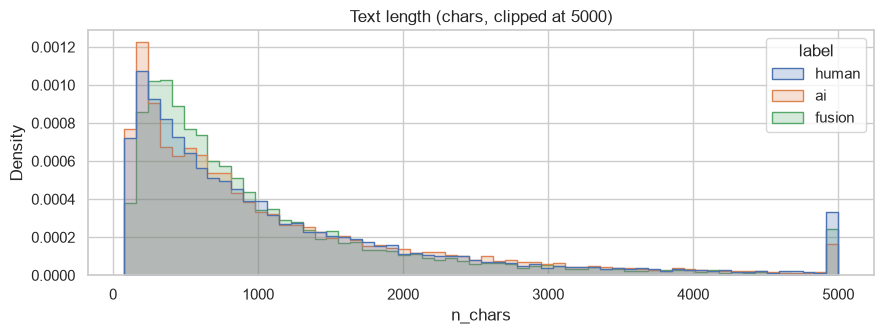

In [1]:
import os, re, time, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TEXT, LANG, DOMAIN, LABEL = "text", "lang", "domain", "label"
CLASSES = ["human", "ai", "fusion"]
BLOG = "blog_authorship_corpus"
COMP = "ai-generated-text-detection-hw3-ucu-ai-2026"
PREFIX_CHARS = 100     # texts sharing their first 100 chars are treated as one group (twins)

def find_data_dir():
    for root in [Path("/kaggle/input"), Path("data"), Path("../data")]:
        if root.exists():
            hits = sorted(root.rglob("train.csv"))
            hits = [h for h in hits if COMP in str(h)] or hits
            if hits:
                return hits[0].parent
    raise FileNotFoundError("train.csv not found: add the competition data as an input")

DATA_DIR = find_data_dir()
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
b = train[(train[DOMAIN] == BLOG) & (train[LANG] == "en-EN")].reset_index(drop=True)
bt = test[(test[DOMAIN] == BLOG) & (test[LANG] == "en-EN")].reset_index(drop=True)
for df in (b, bt):
    df[TEXT] = df[TEXT].fillna("").astype(str)
del train, test
y = b[LABEL].values
print(f"blog train: {len(b):,} | blog test: {len(bt):,}")
display(b[LABEL].value_counts().reindex(CLASSES).to_frame("rows").assign(share=lambda d: (d["rows"] / len(b)).round(3)))

b["n_chars"] = b[TEXT].str.len()
display(b.groupby(LABEL)["n_chars"].describe().reindex(CLASSES).round(0))
plt.figure(figsize=(9, 3.5))
sns.histplot(data=b.assign(n_chars=b["n_chars"].clip(upper=5000)), x="n_chars", hue=LABEL, hue_order=CLASSES,
             bins=60, element="step", stat="density", common_norm=False)
plt.title("Text length (chars, clipped at 5000)"); plt.tight_layout(); plt.show()

## Examples

In [2]:
for lab in CLASSES:
    print(f"\n==================== {lab}")
    for _, r in b[b[LABEL] == lab].sample(4, random_state=3).iterrows():
        print(f"--- {len(r[TEXT]):,} chars: {r[TEXT][:400]!r}")


==================== human
--- 214 chars: '*sigh*..school starts 2maorw and 4me itll be Cempaka.. damansara Heights obviously..Cheras is far like crap...anywayz did nothing 2day..so anyway.. thats it!i`ll try 2 update everyday but doubt so... ~cIa0~ ..-rIz-'
--- 268 chars: 'urlLink Poll shows free speech support down Republican respondents also were more likely than Democrats or Independents to see the news media as too aggressive in seeking war information from government officials. Oh theres a big fucking surprise. Via urlLink Slashdot'
--- 132 chars: "so 'something' calmed me down, and i dont mean what i said last post, but i wish those two would understand how much they fucked up."
--- 1,997 chars: "Korea is, as you may have guessed, a hyper-competitive place. Once a store, restaurant or whatever they always make a big deal of it. One of the best ways they have to get attention is dancing girls. Ya, you heard right. Girls in cheerleader-like outfits dancing up a storm to hiphop in

## Surface markers
Share of texts containing each pattern, per class. Many separate **human vs ai** strongly: `urlLink` and `nbsp` exist only in the original 2004 corpus, while curly apostrophes, em dashes and pictograph emoji are modern LLM habits. `fusion` mostly looks like `human`, because it **is** human text with a few sentences added.

In [3]:
PICTO = "[" + chr(0x1F300) + "-" + chr(0x1FAFF) + chr(0x1F1E6) + "-" + chr(0x1F1FF) + "]"
SYMBOL = "[" + chr(0x2600) + "-" + chr(0x27BF) + "]"
MARKERS = {
    "urlLink": r"urlLink", "html_entity_nbsp": r"nbsp|&\w+;", "http_url": r"https?://",
    "curly_apostrophe": "’", "curly_double_quote": "[“”]", "straight_apostrophe": "'",
    "em_dash": "—", "ellipsis_char": "…", "three_dots": r"\.\.\.", "two_dots_only": r"(?<!\.)\.\.(?!\.)",
    "double_excl": r"!!", "double_quest": r"\?\?", "pictograph_emoji": PICTO, "symbol_emoji": SYMBOL,
    "emoticon": r"(?<![\w:])(?:[:;=][\-^']?[)(\]\[DPpOo3/\\|*]|<3|\^_?\^|[xX]D)(?!\w)",
    "lowercase_i": r"(?<!\w)i(?!\w)", "contraction_no_apostrophe": r"(?i)\b(dont|cant|wont|im|didnt|isnt|doesnt|ive|thats|youre)\b",
    "slang": r"(?i)\b(lol|omg|haha+|lmao|u|ur|r|gonna|wanna|kinda|sorta|ya|cuz|coz|2day|4me|tho|pls|plz)\b",
    "profanity": r"(?i)\b(fuck\w*|shit\w*|damn|crap|ass|bitch\w*)\b",
    "allcaps_word": r"\b[A-Z]{3,}\b", "repeated_letters": r"([a-zA-Z])\1{2,}",
    "missing_space_after_punct": r"[a-z][.,!?][A-Za-z]", "space_before_punct": r"\s[,.!?]",
    "markdown_bold_or_list": r"\*\*|^\s*[-*•]\s", "hashtag": r"#\w", "starts_lowercase": r"^\s*[a-z]",
}
mk = pd.DataFrame({k: b[TEXT].str.contains(p, regex=True) for k, p in MARKERS.items()})
share = mk.groupby(y).mean().T[CLASSES]
share["ai_minus_human"] = share["ai"] - share["human"]
share["fusion_minus_human"] = share["fusion"] - share["human"]
display(share.sort_values("ai_minus_human").style.background_gradient(subset=["ai_minus_human", "fusion_minus_human"],
                                                                    cmap="coolwarm", vmin=-0.4, vmax=0.4).format("{:.3f}"))

,human,ai,fusion,ai_minus_human,fusion_minus_human
urlLink,0.320,0.010,0.230,-0.310,-0.090
starts_lowercase,0.252,0.020,0.188,-0.233,-0.064
three_dots,0.442,0.240,0.422,-0.202,-0.020
lowercase_i,0.216,0.019,0.195,-0.196,-0.020
space_before_punct,0.216,0.033,0.260,-0.183,0.044
profanity,0.196,0.077,0.170,-0.119,-0.026
contraction_no_apostrophe,0.133,0.015,0.113,-0.118,-0.020
allcaps_word,0.392,0.279,0.364,-0.113,-0.028
two_dots_only,0.116,0.005,0.098,-0.111,-0.017
missing_space_after_punct,0.123,0.016,0.096,-0.106,-0.027


## Stylometric + marker features (counts / rates) and their signal
ROC AUC for three pairs: human vs ai, **fusion vs human** (the hard pair), and fusion vs ai. 0.5 means no signal.

In [4]:
WORD = re.compile(r"\w+")
SPL = re.compile(r"(?<=[.!?])\s+")
AI_BLOG_WORDS = ["delve", "journey", "embrace", "vibrant", "honestly", "game-changer", "game changer", "rollercoaster",
                 "a whole new", "let's just say", "can't help but", "couldn't help but", "testament", "navigate",
                 "navigating", "tapestry", "crucial", "ultimately", "absolutely", "literally", "seriously",
                 "anyone else", "who else", "stay tuned", "fellow", "folks", "y'all", "vibe", "vibes", "totally"]
COMPILED = {k: re.compile(p) for k, p in MARKERS.items()}

def blog_features(t):
    words = WORD.findall(t)
    nw, n = max(len(words), 1), max(len(t), 1)
    sents = [s for s in SPL.split(t.strip()) if WORD.search(s)] or [t]
    sl = np.array([len(WORD.findall(s)) for s in sents], dtype=float)
    letters = [c for c in t if c.isalpha()]
    nl = max(len(letters), 1)
    low = t.lower()
    f = {f"m_{k}": len(r.findall(t)) / nw * 100 for k, r in COMPILED.items()}
    f.update({
        "n_chars": len(t), "n_words": len(words), "n_sents": len(sents),
        "avg_sent_len": sl.mean(), "std_sent_len": sl.std(), "burstiness": sl.std() / (sl.mean() + 1e-9),
        "max_sent_len": sl.max(), "avg_word_len": np.mean([len(w) for w in words]) if words else 0.0,
        "ttr": len(set(w.lower() for w in words)) / nw, "upper_ratio": sum(c.isupper() for c in letters) / nl,
        "all_lower": float(len(letters) > 0 and not any(c.isupper() for c in letters)),
        "sent_start_lower": np.mean([s.lstrip()[:1].islower() for s in sents]),
        "digit_ratio": sum(c.isdigit() for c in t) / n, "non_ascii_ratio": sum(ord(c) > 127 for c in t) / n,
        "punct_ratio": sum(c in ".,;:!?-()\"'" for c in t) / n, "comma_per_word": t.count(",") / nw,
        "first_person": len(re.findall(r"\b(i|me|my|mine|myself)\b", low)) / nw * 100,
        "second_person": len(re.findall(r"\b(you|your|yours)\b", low)) / nw * 100,
        "ai_blog_words": sum(low.count(w) for w in AI_BLOG_WORDS) / nw * 100,
        "ends_with_punct": float(t.rstrip()[-1:] in ".!?\"')"),
        "title_like_start": float(bool(re.match(r"^[A-Z][^.!?]{5,80}:\s", t))),
    })
    return f

t0 = time.time()
F = pd.DataFrame([blog_features(t) for t in b[TEXT]])
F_test = pd.DataFrame([blog_features(t) for t in bt[TEXT]])
print(f"{F.shape[1]} features in {time.time() - t0:.0f}s")

def pair_auc(x, y, pos, neg):
    m = np.isin(y, [pos, neg])
    xx, yy = x[m], (y[m] == pos)
    return roc_auc_score(yy, xx) if len(np.unique(xx)) > 1 else 0.5

def auc_table(F, y):
    R = pd.DataFrame({c: {"ai_vs_human": pair_auc(F[c].values, y, "ai", "human"),
                          "fusion_vs_human": pair_auc(F[c].values, y, "fusion", "human"),
                          "fusion_vs_ai": pair_auc(F[c].values, y, "fusion", "ai"),
                          **{f"mean_{k}": F[c].values[y == k].mean() for k in CLASSES}} for c in F.columns}).T
    R["strength"] = (R[["ai_vs_human", "fusion_vs_human", "fusion_vs_ai"]] - 0.5).abs().max(axis=1)
    return R.sort_values("strength", ascending=False)

auc_cols = ["ai_vs_human", "fusion_vs_human", "fusion_vs_ai"]
AUC = auc_table(F, y)
display(AUC.round(3).style.background_gradient(subset=auc_cols, cmap="coolwarm", vmin=0, vmax=1))
print("Best single features for the hard pair (fusion vs human):")
display(AUC.assign(d=(AUC["fusion_vs_human"] - 0.5).abs()).sort_values("d", ascending=False)[["fusion_vs_human"]].head(10).round(3))

47 features in 40s


,ai_vs_human,fusion_vs_human,fusion_vs_ai,mean_human,mean_ai,mean_fusion,strength
non_ascii_ratio,0.847000,0.557000,0.178000,0.001000,0.006000,0.001000,0.347000
m_curly_apostrophe,0.743000,0.536000,0.281000,0.064000,1.201000,0.123000,0.243000
ai_blog_words,0.732000,0.536000,0.305000,0.086000,0.694000,0.177000,0.232000
sent_start_lower,0.301000,0.462000,0.671000,0.227000,0.032000,0.173000,0.199000
avg_word_len,0.686000,0.547000,0.353000,4.114000,4.399000,4.171000,0.186000
digit_ratio,0.333000,0.486000,0.655000,0.005000,0.001000,0.004000,0.167000
m_urlLink,0.345000,0.449000,0.610000,0.734000,0.021000,0.363000,0.155000
comma_per_word,0.653000,0.518000,0.354000,0.042000,0.056000,0.043000,0.153000
burstiness,0.351000,0.484000,0.639000,0.606000,0.488000,0.602000,0.149000
std_sent_len,0.359000,0.500000,0.647000,11.149000,6.930000,10.060000,0.147000


Best single features for the hard pair (fusion vs human):


,fusion_vs_human
ends_with_punct,0.589
non_ascii_ratio,0.557
m_urlLink,0.449
avg_word_len,0.547
upper_ratio,0.458
ttr,0.540
sent_start_lower,0.462
ai_blog_words,0.536
m_curly_apostrophe,0.536
m_starts_lowercase,0.466


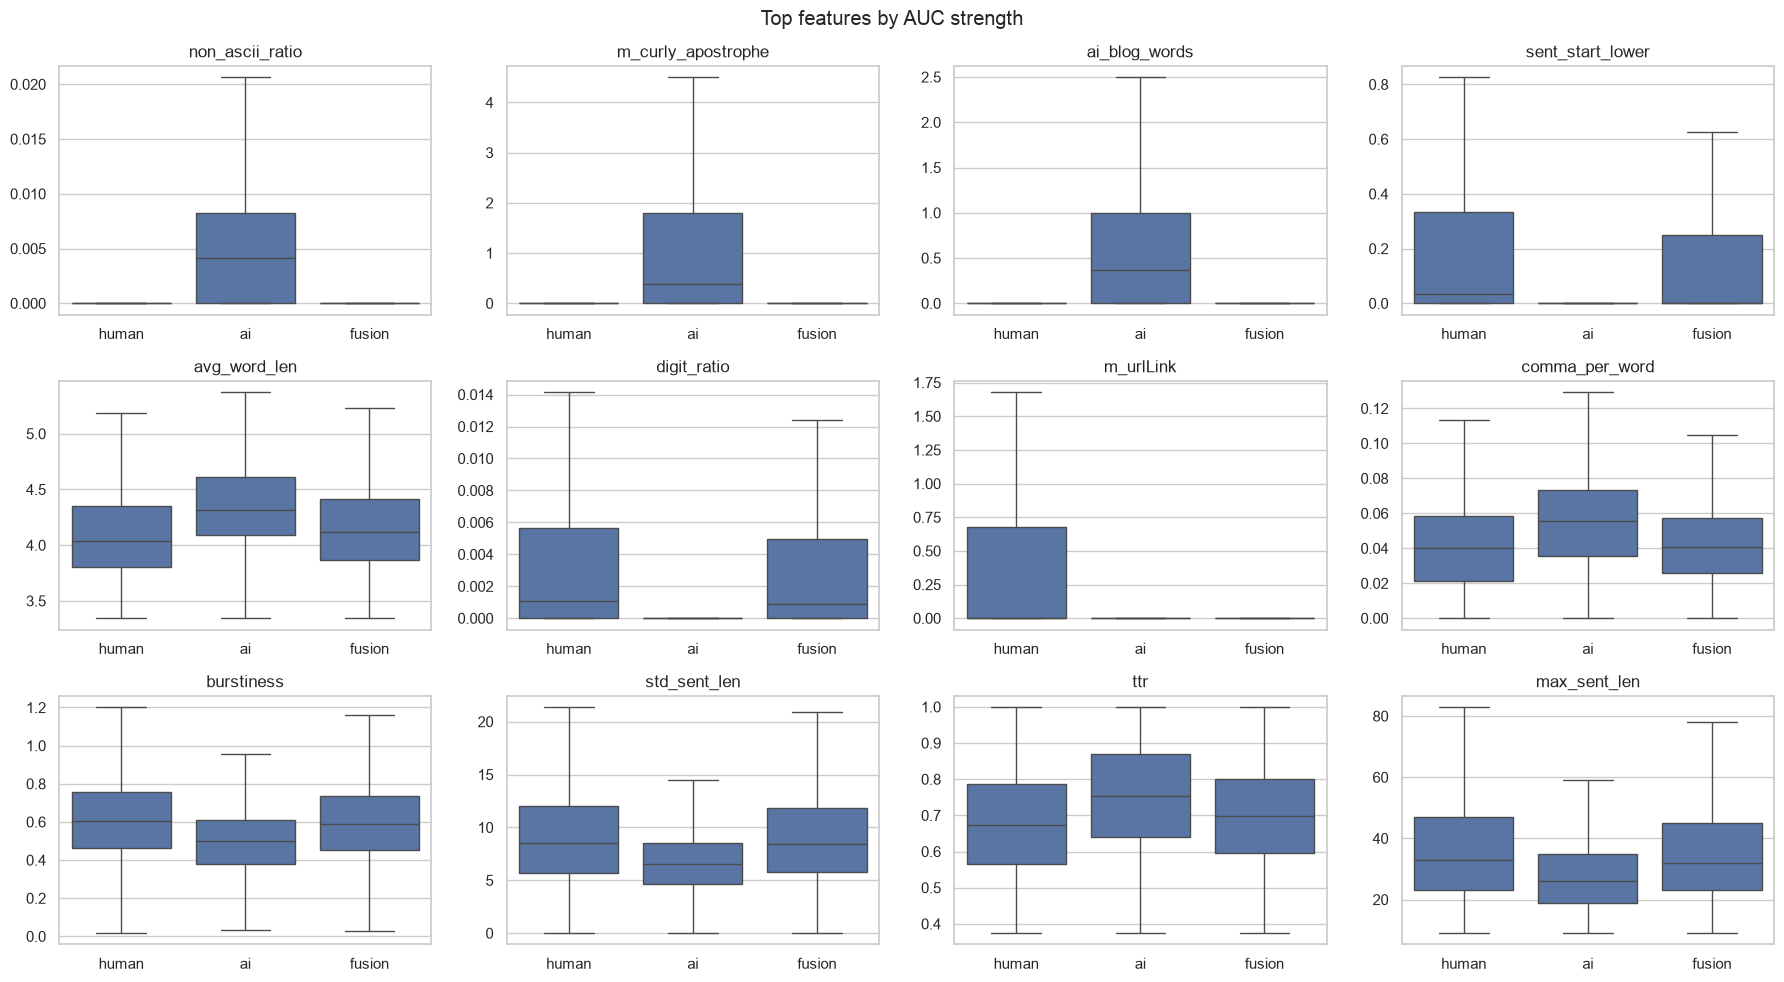

In [5]:
top = AUC.index[:12].tolist()
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.flat, top):
    lo, hi = F[c].quantile([0.01, 0.99])
    sns.boxplot(x=y, y=F[c].clip(lo, hi), order=CLASSES, ax=ax, showfliers=False)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Top features by AUC strength"); plt.tight_layout(); plt.show()

## Vocabulary: most distinctive words and bigrams
Smoothed log-odds ratio of word frequencies: ai vs human, and fusion vs human.

In [6]:
cv = CountVectorizer(ngram_range=(1, 2), min_df=10, max_features=60_000, lowercase=True, token_pattern=r"(?u)\b\w[\w']*\b")
Xc = cv.fit_transform(b[TEXT])
vocab = np.array(cv.get_feature_names_out())

def log_odds(mask_a, mask_b, k=30):
    a = np.asarray(Xc[mask_a].sum(0)).ravel() + 1
    c = np.asarray(Xc[mask_b].sum(0)).ravel() + 1
    lo = np.log(a / a.sum()) - np.log(c / c.sum())
    o = np.argsort(lo)
    return vocab[o[::-1][:k]], vocab[o[:k]]

ai_top, hu_top = log_odds(y == "ai", y == "human")
fu_top, fh_top = log_odds(y == "fusion", y == "human")
display(pd.DataFrame({"ai (vs human)": ai_top, "human (vs ai)": hu_top, "fusion (vs human)": fu_top, "human (vs fusion)": fh_top}))

,ai (vs human),human (vs ai),fusion (vs human),human (vs fusion)
0,whirlwind of,nbsp i,missing section,riz
1,social media,nbsp nbsp,reconstructed missing,hanging by
2,resilience,urllink photographer,reconstructed,gtg
3,a whirlwind,nbsp,the reconstructed,woohoo
4,s talk,by urllink,28 words,de la
5,output text,nbsp the,missing part,urllink via
6,scrolling through,nbsp urllink,crafted to,15 pm
7,final text,nbsp it,section carefully,lim
8,our shared,urllink quizilla,approximately 28,heheex
9,like seriously,nbsp but,section approx,scum


## Human ↔ fusion twins: where are the AI-inserted sentences?
Texts are grouped by their first 100 characters. For each `fusion` text that has a `human` twin, the sentences missing from the human original are the **inserted** ones. The test set has (almost) no twins, so this is a training-data property only. It is useful for understanding fusion and for building sentence labels, but not as a feature.

share of texts that share their opening with another train text, by label:


,share_with_twin
human,0.588
ai,0.000
fusion,0.757


test texts sharing an opening with any train/test text: 0.0016
fusion texts with a human twin: 9,317 of 12,397


,n_sents,n_inserted,share_inserted
count,9317.000,9317.000,9317.000
mean,15.597,1.818,0.174
std,17.043,4.213,0.145
min,1.000,0.000,0.000
25%,6.000,1.000,0.071
50%,10.000,1.000,0.143
75%,19.000,2.000,0.250
max,316.000,143.000,1.000


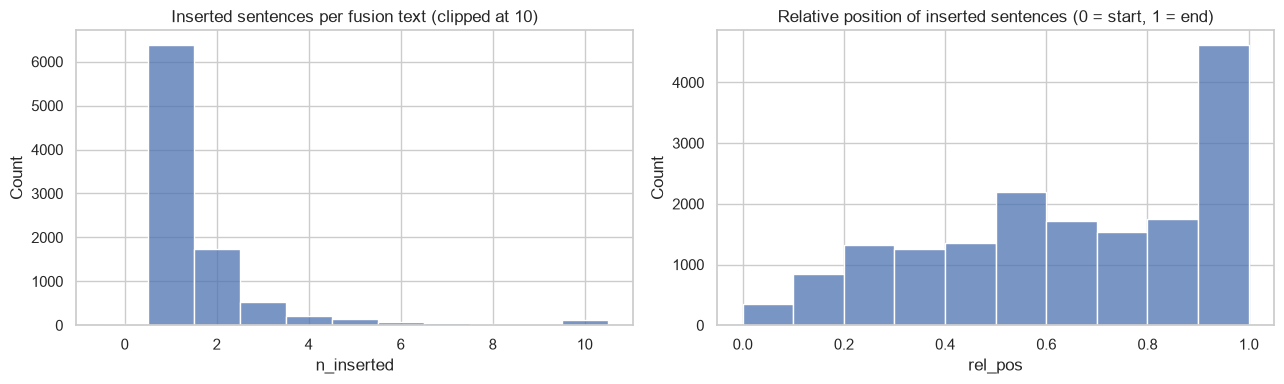


Examples ([[...]] = inserted by the AI):
--- Hellew again~ Eeeee~ Sasak ku ih with this hamster. 3x dah tukar kotak. Im gonna buy a cage for him (the hamster) sometime this week. Sasak kali ah. Abis semua kotak kan digigitnya wa.. Btw..nama the other hamster..bukannya Stitch. Its Furball. [[This time round, I think it's a new one for me.]] Hehe. :p Jumpa my sayang tadi petang d sas. She n her fwen ordered food from McD. Thanx sayang sal 'memajal' me untuk makan. Hehe. :p Jgn mare. *muahz* I really really love her so much. Every moment spent wif her is just so special. U make me sayang u more! Yang..we've been together for 41 days.. Hehe. ;) My sayang called me up tadi..minta dengani buat karangan. We talked for about 30 mins. I hope my sayang nda jadi jalan esok..i wanna call her at home tomorrow. Everything would be fine after dangar suaranya. Hehe. K la. I'll stop for tonite. Love you sayang.
--- How's this for precognition? [[Today I'll go to town, pick up my last pay check (before

In [7]:
b["prefix"] = b[TEXT].str[:PREFIX_CHARS]
b["group"] = b.groupby("prefix").ngroup()
grp_size = b.groupby("group")[LABEL].transform("size")
print("share of texts that share their opening with another train text, by label:")
display((grp_size > 1).groupby(y).mean().reindex(CLASSES).round(3).to_frame("share_with_twin"))
pref_all = pd.concat([b["prefix"], bt[TEXT].str[:PREFIX_CHARS]]).value_counts()
print("test texts sharing an opening with any train/test text:", round((bt[TEXT].str[:PREFIX_CHARS].map(pref_all) > 1).mean(), 4))

human_by_prefix = b[b[LABEL] == "human"].groupby("prefix")[TEXT].first()

def split_sents(t):
    return [s.strip() for s in SPL.split(t) if s.strip()]

ins_rows, ins_sent = [], []
for i, r in b[(b[LABEL] == "fusion") & b["prefix"].isin(human_by_prefix.index)].iterrows():
    src = set(split_sents(human_by_prefix[r["prefix"]]))
    fs = split_sents(r[TEXT])
    new = [k for k, s in enumerate(fs) if s not in src]
    ins_rows.append({"idx": i, "n_sents": len(fs), "n_inserted": len(new), "share_inserted": len(new) / max(len(fs), 1)})
    for k in new:
        ins_sent.append({"idx": i, "pos": k, "rel_pos": k / max(len(fs) - 1, 1), "sentence": fs[k],
                         "prev": fs[k - 1] if k > 0 else "", "next": fs[k + 1] if k + 1 < len(fs) else ""})
ins_rows, ins_sent = pd.DataFrame(ins_rows), pd.DataFrame(ins_sent)
print(f"fusion texts with a human twin: {len(ins_rows):,} of {(y == 'fusion').sum():,}")
display(ins_rows[["n_sents", "n_inserted", "share_inserted"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ins_rows["n_inserted"].clip(upper=10), discrete=True, ax=axes[0]); axes[0].set_title("Inserted sentences per fusion text (clipped at 10)")
sns.histplot(ins_sent["rel_pos"], bins=10, ax=axes[1]); axes[1].set_title("Relative position of inserted sentences (0 = start, 1 = end)")
plt.tight_layout(); plt.show()

print("\nExamples ([[...]] = inserted by the AI):")
for i in ins_rows.sample(4, random_state=5)["idx"]:
    src = set(split_sents(human_by_prefix[b.loc[i, "prefix"]]))
    print("---", " ".join(f"[[{s}]]" if s not in src else s for s in split_sents(b.loc[i, TEXT]))[:900])

### What does an inserted sentence look like?
Inserted sentences compared with the **original human sentences of the same texts**. Features with AUC far from 0.5 can flag an inserted sentence on their own.

In [8]:
def sent_features(s):
    w = WORD.findall(s)
    nw = max(len(w), 1)
    return {"n_words": len(w), "avg_word_len": np.mean([len(x) for x in w]) if w else 0.0,
            "starts_upper": float(s[:1].isupper()), "ends_punct": float(s.rstrip()[-1:] in ".!?"),
            "curly_apostrophe": float("’" in s), "straight_apostrophe": float("'" in s), "em_dash": float("—" in s),
            "comma_rate": s.count(",") / nw, "lowercase_i": float(bool(re.search(r"(?<!\w)i(?!\w)", s))),
            "contraction_no_apos": float(bool(re.search(r"(?i)\b(dont|cant|im|didnt|thats)\b", s))),
            "slang": float(bool(re.search(r"(?i)\b(lol|u|ur|gonna|wanna|haha+)\b", s))),
            "non_ascii": sum(ord(c) > 127 for c in s) / max(len(s), 1),
            "ai_blog_words": sum(s.lower().count(x) for x in AI_BLOG_WORDS)}

orig = []
for i in ins_rows["idx"]:
    src = set(split_sents(human_by_prefix[b.loc[i, "prefix"]]))
    orig += [s for s in split_sents(b.loc[i, TEXT]) if s in src]
S_ins = pd.DataFrame([sent_features(s) for s in ins_sent["sentence"]])
S_orig = pd.DataFrame([sent_features(s) for s in orig])
cmp = pd.DataFrame({c: {"inserted_mean": S_ins[c].mean(), "original_mean": S_orig[c].mean(),
                        "AUC_inserted_vs_original": roc_auc_score(np.r_[np.ones(len(S_ins)), np.zeros(len(S_orig))],
                                                                  np.r_[S_ins[c], S_orig[c]])} for c in S_ins.columns}).T
display(cmp.sort_values("AUC_inserted_vs_original").round(3).style.background_gradient(
    subset=["AUC_inserted_vs_original"], cmap="coolwarm", vmin=0.2, vmax=0.8))

ins_vocab = CountVectorizer(ngram_range=(1, 2), min_df=5, token_pattern=r"(?u)\b\w[\w']*\b")
Xi = ins_vocab.fit_transform(list(ins_sent["sentence"]) + orig)
vv = np.array(ins_vocab.get_feature_names_out())
a = np.asarray(Xi[:len(ins_sent)].sum(0)).ravel() + 1
c = np.asarray(Xi[len(ins_sent):].sum(0)).ravel() + 1
lo = np.log(a / a.sum()) - np.log(c / c.sum())
display(pd.DataFrame({"inserted (vs original)": vv[np.argsort(-lo)[:30]], "original (vs inserted)": vv[np.argsort(lo)[:30]]}))

,inserted_mean,original_mean,AUC_inserted_vs_original
starts_upper,0.697000,0.758000,0.470000
ends_punct,0.950000,1.000000,0.475000
lowercase_i,0.026000,0.072000,0.477000
contraction_no_apos,0.013000,0.019000,0.497000
slang,0.014000,0.018000,0.498000
straight_apostrophe,0.316000,0.290000,0.513000
em_dash,0.036000,0.001000,0.517000
curly_apostrophe,0.066000,0.017000,0.525000
ai_blog_words,0.067000,0.012000,0.526000
comma_rate,0.040000,0.039000,0.526000


,inserted (vs original),original (vs inserted)
0,missing section,photo of
1,reconstructed,urllink photographer
2,reconstructed missing,boinking
3,the reconstructed,love boinking
4,28 words,gene
5,missing part,finny
6,crafted to,photographer
7,section carefully,comments this
8,seamlessly,used canon
9,approximately 28,my sayang


## Sentence-level AI detector, aggregated per text
Training sentences:
- **AI** (label 1): the inserted sentences from fusion twins, plus up to 3 sentences per `ai` text.
- **Human** (label 0): sentences from `human` texts.

Model: TF-IDF (char 2–5 + word 1–2) + logistic regression. Out-of-fold with `GroupKFold` over twin groups, so a text's sentences are always scored by a model that never saw the text or its twin.

Per-text features: max, mean of the top 2, mean, std, count and share of sentences above 0.5, max minus median (an outlier sentence), and position of the most AI-like sentence.

fold 1/5 | held-out AUC inserted-vs-human sentences = 0.893 (77s)
fold 2/5 | held-out AUC inserted-vs-human sentences = 0.893 (152s)
fold 3/5 | held-out AUC inserted-vs-human sentences = 0.888 (228s)
fold 4/5 | held-out AUC inserted-vs-human sentences = 0.890 (307s)
fold 5/5 | held-out AUC inserted-vs-human sentences = 0.892 (381s)


,ai_vs_human,fusion_vs_human,fusion_vs_ai,mean_human,mean_ai,mean_fusion,strength
sent_ai_mean,0.996000,0.761000,0.020000,0.183000,0.784000,0.300000,0.496000
sent_ai_share_over_05,0.988000,0.763000,0.028000,0.104000,0.836000,0.241000,0.488000
sent_ai_max,0.978000,0.844000,0.210000,0.536000,0.977000,0.854000,0.478000
sent_ai_top2,0.977000,0.769000,0.105000,0.453000,0.956000,0.705000,0.477000
sent_ai_max_minus_median,0.202000,0.755000,0.947000,0.405000,0.131000,0.644000,0.447000
sent_ai_n_over_05,0.920000,0.685000,0.127000,1.542000,11.231000,2.537000,0.420000
sent_ai_std,0.624000,0.829000,0.724000,0.161000,0.199000,0.280000,0.329000
sent_ai_argmax_relpos,0.472000,0.555000,0.583000,0.498000,0.463000,0.564000,0.083000
n_sentences,0.520000,0.509000,0.486000,14.936000,13.493000,13.697000,0.020000


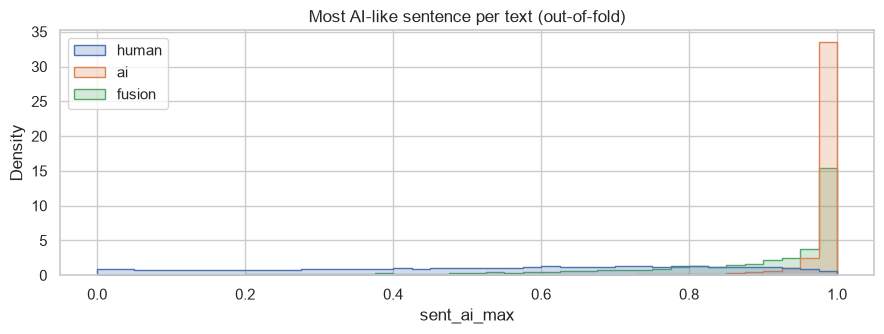

In [9]:
SENTS = [split_sents(t) or [t] for t in b[TEXT]]
SENTS_TEST = [split_sents(t) or [t] for t in bt[TEXT]]
INS = ins_sent.groupby("idx")["sentence"].apply(list).to_dict()
groups = b["group"].values
gkf = GroupKFold(n_splits=5)
FOLDS = list(gkf.split(np.zeros(len(b)), y, groups))
rng = np.random.default_rng(RANDOM_STATE)

def sentence_training_data(doc_idx):
    X, Y = [], []
    for i in doc_idx:
        if y[i] == "human":
            X += SENTS[i]; Y += [0] * len(SENTS[i])
        elif y[i] == "ai":
            ss = SENTS[i] if len(SENTS[i]) <= 3 else list(rng.choice(SENTS[i], 3, replace=False))
            X += ss; Y += [1] * len(ss)
        elif i in INS:
            X += INS[i]; Y += [1] * len(INS[i])
    return X, Y

def fit_sentence_model(doc_idx):
    X, Y = sentence_training_data(doc_idx)
    wv = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=3, max_features=200_000, token_pattern=r"(?u)\b\w[\w']*\b")
    cv_ = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=5, max_features=300_000, lowercase=False)
    M = sp.hstack([wv.fit_transform(X), cv_.fit_transform(X)]).tocsr()
    clf = LogisticRegression(C=2, max_iter=2000, class_weight="balanced").fit(M, Y)
    return wv, cv_, clf

def score_sentences(model, sent_lists):
    wv, cv_, clf = model
    flat = [s for ss in sent_lists for s in ss]
    p = clf.predict_proba(sp.hstack([wv.transform(flat), cv_.transform(flat)]).tocsr())[:, 1]
    out, k = [], 0
    for ss in sent_lists:
        out.append(p[k:k + len(ss)]); k += len(ss)
    return out

def sentence_summary(scores):
    rows = []
    for s in scores:
        srt = np.sort(s)[::-1]
        rows.append({"sent_ai_max": srt[0], "sent_ai_top2": srt[:2].mean(), "sent_ai_mean": s.mean(), "sent_ai_std": s.std(),
                     "sent_ai_n_over_05": float((s > .5).sum()), "sent_ai_share_over_05": (s > .5).mean(),
                     "sent_ai_max_minus_median": srt[0] - np.median(s), "sent_ai_argmax_relpos": s.argmax() / max(len(s) - 1, 1),
                     "n_sentences": len(s)})
    return pd.DataFrame(rows)

t0 = time.time()
sent_scores = [None] * len(b)
heldout_auc = []
for f_i, (tr, te) in enumerate(FOLDS):
    model = fit_sentence_model(tr)
    for i, s in zip(te, score_sentences(model, [SENTS[i] for i in te])):
        sent_scores[i] = s
    # sentence-level check: held-out inserted sentences vs held-out human sentences
    Xi_, Yi_ = [], []
    for i in te:
        if i in INS:
            Xi_ += INS[i]; Yi_ += [1] * len(INS[i])
        elif y[i] == "human":
            Xi_ += SENTS[i]; Yi_ += [0] * len(SENTS[i])
    p = score_sentences(model, [Xi_])[0]
    heldout_auc.append(roc_auc_score(Yi_, p))
    print(f"fold {f_i + 1}/5 | held-out AUC inserted-vs-human sentences = {heldout_auc[-1]:.3f} ({time.time() - t0:.0f}s)", flush=True)

SF = sentence_summary(sent_scores)
display(auc_table(SF, y).round(3).style.background_gradient(subset=auc_cols, cmap="coolwarm", vmin=0, vmax=1))

plt.figure(figsize=(9, 3.5))
sns.histplot(x=SF["sent_ai_max"], hue=y, hue_order=CLASSES, bins=40, element="step", stat="density", common_norm=False)
plt.title("Most AI-like sentence per text (out-of-fold)"); plt.tight_layout(); plt.show()

## Model comparison (5-fold GroupKFold, blog only)
- TF-IDF (word 1–2 + char 3–5) + logistic regression on whole texts.
- Gradient boosting on: handcrafted features; handcrafted + sentence-detector features; and a stack that also includes the TF-IDF out-of-fold probabilities.

Sentence features and TF-IDF probabilities are out-of-fold, but computed once rather than nested. The stack's score can therefore be slightly optimistic; treat it as a direction.

In [ ]:
def report(name, pred):
    f = f1_score(y, pred, average=None, labels=CLASSES)
    return {"model": name, "macro_f1": f1_score(y, pred, average="macro"), "f1_human": f[0], "f1_ai": f[1], "f1_fusion": f[2]}

t0 = time.time()
tfidf_proba = np.zeros((len(b), 3))
tfidf_pred = np.empty(len(b), dtype=object)
for tr, te in FOLDS:
    wv = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_features=300_000)
    cv_ = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True, min_df=3, max_features=300_000, lowercase=False)
    Xtr = sp.hstack([wv.fit_transform(b[TEXT].values[tr]), cv_.fit_transform(b[TEXT].values[tr])]).tocsr()
    Xte = sp.hstack([wv.transform(b[TEXT].values[te]), cv_.transform(b[TEXT].values[te])]).tocsr()
    lr = LogisticRegression(C=8, max_iter=2000).fit(Xtr, y[tr])
    tfidf_proba[te] = lr.predict_proba(Xte)[:, [list(lr.classes_).index(c) for c in CLASSES]]
    tfidf_pred[te] = lr.predict(Xte)
print(f"TF-IDF OOF done in {time.time() - t0:.0f}s")

hgb = lambda: HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, random_state=RANDOM_STATE)
def cv_hgb(X):
    p = np.empty(len(b), dtype=object)
    for tr, te in FOLDS:
        p[te] = hgb().fit(X[tr], y[tr]).predict(X[te])
    return p

results = [report("TF-IDF word+char + LogReg", tfidf_pred)]
preds = {"TF-IDF word+char + LogReg": tfidf_pred}
for name, X in {"handcrafted (HGB)": F.values,
                "handcrafted + sentence detector (HGB)": np.hstack([F.values, SF.values]),
                "stack: + TF-IDF probabilities (HGB)": np.hstack([F.values, SF.values, tfidf_proba])}.items():
    preds[name] = cv_hgb(X)
    results.append(report(name, preds[name]))
res = pd.DataFrame(results).set_index("model")
display(res.style.background_gradient(cmap="Greens", vmin=0.5, vmax=1).format(precision=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, [res.index[0], res.index[-1]]):
    cm = confusion_matrix(y, preds[name], labels=CLASSES)
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

### Which feature groups matter? (drop one group, handcrafted + sentence model)

In [ ]:
GROUPS = {
    "markers (m_*)": [c for c in F.columns if c.startswith("m_")],
    "length": ["n_chars", "n_words", "n_sents"],
    "rhythm": ["avg_sent_len", "std_sent_len", "burstiness", "max_sent_len", "avg_word_len", "ttr"],
    "casing": ["upper_ratio", "all_lower", "sent_start_lower"],
    "other style": ["digit_ratio", "non_ascii_ratio", "punct_ratio", "comma_per_word", "first_person", "second_person",
                    "ai_blog_words", "ends_with_punct", "title_like_start"],
}
base = f1_score(y, preds["handcrafted + sentence detector (HGB)"], average="macro")
abl = [{"dropped": "(none)", "macro_f1": base, "delta": 0.0},
       {"dropped": "sentence detector", "macro_f1": (s := f1_score(y, preds["handcrafted (HGB)"], average="macro")), "delta": s - base}]
for gname, cols in GROUPS.items():
    s = f1_score(y, cv_hgb(np.hstack([F.drop(columns=cols).values, SF.values])), average="macro")
    abl.append({"dropped": gname, "macro_f1": s, "delta": s - base})
display(pd.DataFrame(abl).style.background_gradient(subset=["delta"], cmap="RdYlGn", vmin=-0.05, vmax=0.05).format(precision=3))

## Errors of the best model

In [ ]:
best = res["macro_f1"].idxmax()
e = b.assign(pred=preds[best])
e = e[e[LABEL] != e["pred"]]
print(f"best: {best} | errors: {len(e):,}")
display(e.groupby([LABEL, "pred"]).size().sort_values(ascending=False).rename("n").to_frame())
e_len = pd.qcut(b["n_chars"], 5)
print("macro-F1 of the best model by text length:")
display(pd.DataFrame({str(k): {"n": len(gr), "macro_f1": f1_score(y[gr.index], preds[best][gr.index], average="macro")}
                      for k, gr in b.groupby(e_len, observed=True)}).T.round(3))
for (t, pr), gr in e.groupby([LABEL, "pred"]):
    print(f"\n--- true={t} -> pred={pr} ({len(gr)})")
    for _, row in gr.sample(min(2, len(gr)), random_state=RANDOM_STATE).iterrows():
        print("   ", repr(row[TEXT][:300]))

## Export features for blog train + test
Test rows: the sentence detector is trained on all blog train texts. Train rows keep their out-of-fold sentence scores. Merge into other pipelines by `id`.

In [ ]:
SF_test = sentence_summary(score_sentences(fit_sentence_model(np.arange(len(b))), SENTS_TEST))
out = pd.concat([
    pd.concat([b[["id", LABEL]].assign(split="train"), F, SF], axis=1),
    pd.concat([bt[["id"]].assign(split="test", **{LABEL: np.nan}), F_test, SF_test], axis=1),
], ignore_index=True)
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
out.to_csv(OUT_DIR / "blog_features.csv", index=False)
print(f"saved {(OUT_DIR / 'blog_features.csv').resolve()} {out.shape}")
display(out.groupby(["split", LABEL], dropna=False)[["sent_ai_max", "sent_ai_n_over_05", "m_urlLink", "m_curly_apostrophe", "burstiness"]]
        .mean().round(3))

## What to look at when reading the results
- **Markers table / AUC table**: which signals separate `ai` from `human` almost perfectly (expected: `urlLink`, `nbsp`, curly apostrophes, em dashes, emoji), and which, if any, help with `fusion` vs `human`.
- **Twin analysis**: how many sentences the AI inserts, and where. If it is usually 1–2 sentences, whole-text features are diluted, and sentence-level features are the way to catch fusion.
- **Inserted-sentence table**: the concrete properties of inserted sentences, e.g. correct capitalisation, curly apostrophes, no slang, in texts that otherwise have lowercase `i` and `dont`. These **style breaks against the rest of the text** are candidate features.
- **Model comparison**: whether the sentence detector improves `fusion` F1 over TF-IDF, and whether stacking adds more.
- **Validation caveat for other notebooks**: a random train/validation split puts twins on both sides, so blog validation scores there are optimistic for fusion and human.